# 1- This code is for the simulation of Acetyl-CoA, Malonyl-CoA FA, TG model for the two regimes: degradation and synthesis of TAG
The code serve to test the multistability in the "blind way". Indeed for a fix values of parameters, we varies initial conditions randomly and observe the steady state.
<div>
<img src="Acetyl_CoA_vs_TAG.gif" width="500"/>
</div>



In [1]:
import numpy as np
import random as rd
import pandas as pd
import scipy.integrate as sp
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from Rate_laws import *

## We get the parameters from databses 
Km1 = 0.034 at  37°C	Homo sapiens(Brenda), Km1 = 0.058	acetyl-CoA	at 37°C	Homo sapiens (Brenda)
kcat1 = 10.1  and  11.8 (Brenda)
Ki1 = 1/q1 = 0.0008,	 palmitoyl-CoA	is the inhibitor Homo sapiens (Brenda)

Km2 = 0.001, malonyl-CoA as subtrate  temp = 25°C, pH = 7.0, mutant enzyme K1699Q in 	Homo sapiens	
      0.003, malonyl-CoA as substrate temp = 25°C, pH = 7.0, mutant enzyme K1699A in 	Homo sapiens	
      0.006, malonyl-CoA as substrate temp = 25°C, pH = 7.0, wild-type enzyme	  in    Homo sapiens	
Kcat2 = 0.3, malonyl-CoA as substrate 	                     mutant enzyme K1699Q in 	Homo sapiens	
        0.32,malonyl-CoA as substrate                        mutant enzyme K1699A in    Homo sapiens	
        2.7, malonyl-CoA as substrate                        wild-type enzyme	  in    Homo sapiens	     
        
        
        
   Km4 =0.0679, Palmitoyl-CoA as substrate		Homo sapiens	-	wild-type enzyme

In [2]:
time = np.linspace(0, 10, 1000)

par = {
    "a1": 1.0,
    "a2": 0.0,
    "a3": 1.0,
    "alpha1": 1.0,
    "alpha2": 0.0,
    "alpha3": 1.0,
    "V1": 1.0,
    "V2": 1.0,
    "V3": 1.0,
    "V4": 1.0,
    "V5": 1.0,
    "Km1": 1.0,
    "Km2": 1.0,
    "Km3": 1.0,
    "Km4": 1.0,
    "Km5": 1.0,
    "q1": 1.0,
    "q4": 1.0,
     "y0": 1.0
}


In [3]:

compounds = ["Acetyl_CoA", "Malonyl_CoA", "Fatty_Acyl", "TAG"]

n_compounds = len(compounds)

y0 = np.zeros(n_compounds)



In [4]:
# In this part we define the rate equations for each reactions


def get_rates(y, par):
    Acetyl_CoA, Malonyl_CoA, Fatty_Acyl, TAG = y

    reactions = {
        "v_in_1":
        constant_influx(par["a1"]),
        "v_in_2":
        constant_influx(par["a2"]),

        # "v_in_3": constant_influx(par["Kin3"]),
        "v_in_3":
        constant_influx(par["a3"]),
        "r1":
        non_competitive_inhibition(par["V1"], par["Km1"], par["q1"],
                                   Acetyl_CoA, Fatty_Acyl),
        "r2":
        michaelis_meten(par["V2"], par["Km2"], Malonyl_CoA),
        "r3":
        michaelis_meten(par["V3"], par["Km3"], Fatty_Acyl),
        "r4":
        non_competitive_inhibition(par["V4"], par["Km4"], par["q4"],
                                   Fatty_Acyl, Malonyl_CoA),
        "r5":
        michaelis_meten(par["V5"], par["Km5"], TAG),
        "v_out1":
        mass_action_simple(par["alpha1"], Acetyl_CoA),
        "v_out2":
        mass_action_simple(par["alpha2"], Fatty_Acyl),
        "v_out3":
        mass_action_simple(par["alpha3"], TAG),
    }
    return reactions

In [5]:
# The individual reactions are put together to describe the dynamic of the system as ODE


def model(time, y, par):
    rates = get_rates(y=y, par=par)
    d_Acetyl_CoA_dt = (rates["v_in_1"] - rates["r1"] + rates["r4"] -
                       rates["v_out1"])
    d_Malony_CoA = rates["r1"] - rates["r2"]

    d_Fatty_Acyl = (rates["v_in_2"] + rates["r2"] - 3*rates["r3"] - rates["r4"] +
                   3*rates["r5"] - rates["v_out2"])

    d_TAG_dt = rates["v_in_3"] + 3*rates["r3"] - 3*rates["r5"] - rates["v_out3"]

    return np.array([d_Acetyl_CoA_dt, d_Malony_CoA, d_Fatty_Acyl, d_TAG_dt])

In [6]:
def simulate_steady_state(model, y0, par, dt=1e-3, error=1e-5, max_steps=1e3):
    r = sp.ode(model)
    r.set_integrator("lsoda", method="bdf")
    r.set_f_params(par)
    r.set_initial_value(y0, 0.0)

    y1 = y0.copy()
    nsteps = 0
    while r.successful and nsteps < max_steps:
        y2 = r.integrate(r.t + dt)
        if np.linalg.norm(y1 - y2, ord=2) < error:
            return y2
        else:
            y1 = y2
        nsteps += 1
    raise ValueError("Maximal simulation steps exceeded")

## 1.1- Case of synthesis of triglycerides  no outflux of Acetyl- CoA and no in flux of trigycerides. The influx and                                       the outflux  of fatty acids are set to 0.

In [19]:
par1 = par.copy()
par1.update({"a1":1.0, "alpha1": 1.0,"alpha2": 0.0, "alpha3":1.0, "a2":0.0, "a3":0.0, "V3":1.0, "V2":1.0, "V1":1.0})
par1

{'a1': 1.0,
 'a2': 0.0,
 'a3': 0.0,
 'alpha1': 1.0,
 'alpha2': 0.0,
 'alpha3': 1.0,
 'V1': 1.0,
 'V2': 1.0,
 'V3': 1.0,
 'V4': 1.0,
 'V5': 1.0,
 'Km1': 1.0,
 'Km2': 1.0,
 'Km3': 1.0,
 'Km4': 1.0,
 'Km5': 1.0,
 'q1': 1.0,
 'q4': 1.0,
 'y0': 1.0}

In [20]:
# Solve the differential equations

y = sp.odeint(func=model, y0=y0, t=time, args=(par1, ), tfirst=True)

# Simulate the steady state
steady1 = list(simulate_steady_state(model, y0, par1, dt=100))

In [21]:
steady1

[0.8051645552514052,
 0.5251662631392315,
 0.29535325792260353,
 0.19483544474861514]

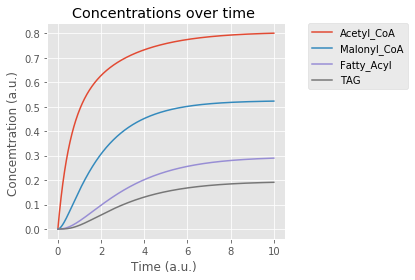

In [22]:
plt.style.use('ggplot')
fig, ax = plt.subplots()
ax.plot(time, y)
plt.xlabel("Time (a.u.) ")
plt.ylabel("Concemtration (a.u.) ")
plt.title("Concentrations over time ")
ax.legend(compounds,
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0)
plt.tight_layout()
plt.savefig("Concentrations_1.png", bbox_inches='tight')
plt.show()

### Variation of the internal concentration (Malony-CoA and Fatty Acyl) with the change of parameters.

In [23]:
# Vary the value of a1
Var_a1 = [i for i in np.linspace(0, 1, 100)]
Steady_state_concentration = []
for i in Var_a1:
    par1.update({"a1": i})
    Steady_state_concentration.append(simulate_steady_state(model, y0, par1, dt=100))

A = Var_a1
B = Steady_state_concentration


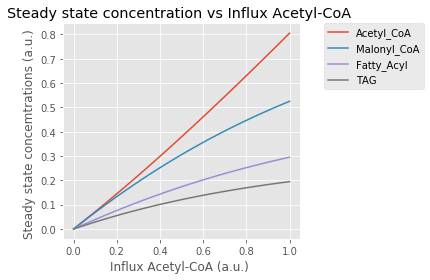

In [24]:
plt.style.use("ggplot")
fig, ax = plt.subplots()
ax.plot(A, B)
plt.xlabel("Influx Acetyl-CoA (a.u.) ")
plt.ylabel("Steady state concemtrations (a.u.) ")
plt.title("Steady state concentration vs Influx Acetyl-CoA ")
ax.legend(compounds, loc="upper left", bbox_to_anchor=(1.1, 1), borderaxespad=0)
plt.tight_layout()
plt.savefig("Concentrations_1.png", bbox_inches="tight")
plt.show()

## 1.2 Case of degradation of triglycerides  no outflux of triglycerides and no influx of acetyl-CoA. The influx and                                       the outflux  of fatty acids are set to 0.

In [15]:

par2 = par.copy()
par2.update({"a1":0.0, "alpha1": 1.0,"alpha2": 0.0, "alpha3":0.0, "a2":0.0, "a3":0.40, "V5":5.0, "V4":1.0})
par2

{'a1': 0.0,
 'a2': 0.0,
 'a3': 0.4,
 'alpha1': 1.0,
 'alpha2': 0.0,
 'alpha3': 0.0,
 'V1': 1.0,
 'V2': 1.0,
 'V3': 1.0,
 'V4': 1.0,
 'V5': 5.0,
 'Km1': 1.0,
 'Km2': 1.0,
 'Km3': 1.0,
 'Km4': 1.0,
 'Km5': 1.0,
 'q1': 1.0,
 'q4': 1.0,
 'y0': 1.0}

In [16]:
z = sp.odeint(func=model, y0=y0, t=time, args=(par2, ), tfirst=True)
steady2 = list(simulate_steady_state(model, y0, par2, dt=100))
steady2

[0.4000000022697241,
 0.13371369890341234,
 1.4224758119571506,
 0.16836966664338385]

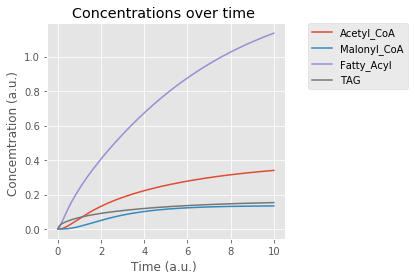

In [17]:
plt.style.use('ggplot')
fig, ax = plt.subplots()
ax.plot(time, z)
plt.xlabel("Time (a.u.) ")
plt.ylabel("Concemtration (a.u.) ")
plt.title("Concentrations over time ")
ax.legend(compounds,
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0)
plt.tight_layout()
plt.savefig("Concentrations_2.png", bbox_inches='tight')
plt.show()

### Variation of the internal concentration (Malony-CoA and Fatty Acyl) with the change of parameters.

In [18]:
# Vary the value of a3
Var_a3 = [i for i in np.linspace(0, 0.5, 100)]
Steady_state_concentration = []
for i in Var_a3:
    par2.update({"a3": i})
    Steady_state_concentration.append(simulate_steady_state(model, y0, par2, dt=100))

A = Var_a3
B = Steady_state_concentration

In [ ]:
plt.style.use("ggplot")
fig, ax = plt.subplots()
ax.plot(A, B)
plt.xlabel("Influx TAG (a.u.) ")
plt.ylabel("Steady state concemtrations (a.u.) ")
plt.title("Steady state concentration vs Influx TAG ")
ax.legend(compounds, loc="upper left", bbox_to_anchor=(1.1, 1), borderaxespad=0)
plt.tight_layout()
plt.savefig("Concentrations_1.png", bbox_inches="tight")
plt.show()